# 05. 과거 시계열 특징과 누수 없는 학습 데이터

원시 관측을 한 번에 적재하지 않고 장비별 Parquet 배치를 읽었습니다. 전체 라벨은 모든 정규화 관측 시각에 보존하고, 특징은 **60 원시시간 단위 bin에서 첫 실제 관측 시각**에 생성합니다. 마지막 행이나 bin 평균을 미래 시점에서 되돌려 붙이지 않습니다. 선택 주기는 라벨과 무관하고 학습·검증·평가 모두 동일합니다. 원래 모든 시점의 라벨은 별도 Parquet에 유지됩니다.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.dataset_common import DEST,REPORT,POLICY,FAULTS,SENSORS,HORIZONS,feature_columns,label_columns
summary=json.loads((REPORT/"dataset_summary.json").read_text(encoding="utf-8"))
assert summary["all_checks_passed"]
assert len(summary["tools"])==20,"전체 장비 구축·검증을 먼저 완료하세요."
full=pd.DataFrame(summary["full_counts"])
ready=pd.DataFrame(summary["ready_counts"])
events=pd.DataFrame(summary["fault_events"])
plt.rcParams.update({"font.family":"Malgun Gothic","axes.unicode_minus":False,"figure.dpi":110})
pd.set_option("display.max_columns",30)
def save_figure(fig,name):
    folder=REPORT/"figures";folder.mkdir(exist_ok=True)
    fig.savefig(folder/(name+".png"),dpi=130,bbox_inches="tight")
    plt.show()
print("실행 Python:",sys.executable)
print("데이터 경로:",DEST)

실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
데이터 경로: C:\Users\fl27\Documents\ChatGPT\PHM2018-Project\data\processed\ml_v1


## 특징 정의 및 입력 허용 목록

6개 센서의 현재값과 각 w=60/300 원시시간 구간의 평균·표준편차(ddof=0)·최솟값·최댓값을 사용합니다. 현재 구간은 `(t-w,t]`, 이전 구간은 `(t-2w,t-w]`입니다. 평균 변화량은 두 구간 평균의 차이, 변화율은 그 차이를 w로 나눈 값입니다. 물리 분 또는 백분율 변화로 해석하지 않습니다.

현재 Recipe/Stage와 과거 300 원시단위의 Stage=0 비율, Recipe/Stage 전환 횟수를 추가합니다. 입력은 센서·현재/과거 공정 정보의 명시적 목록만 허용합니다. TTF·fault·라벨·다음 이벤트·분할·미래 세그먼트 종료 시각은 입력에서 제외합니다.

In [2]:
features=feature_columns()
display(pd.DataFrame({"입력 특징":features}))
print("특징 수:",len(features))
from src.dataset_loader import iter_model_batches
X_example,y_example=next(iter_model_batches("label_any_h300raw","train",batch_size=256))
print("안전한 로더 입력/타깃 크기:",X_example.shape,y_example.shape)
assert X_example.columns.tolist()==features and not y_example.isna().any()
display(pd.DataFrame(summary["checks"]))
build_rows=[json.loads((REPORT/f"features_{t}.json").read_text(encoding="utf-8")) for t in summary["tools"]]
display(pd.DataFrame(build_rows))
display(Markdown(f"총 anchor **{summary['anchor_rows']:,}개** 중 특징 이력이 충분한 행은 **{summary['feature_ready_rows']:,}개**입니다. 앞선 600 원시단위의 연속 이력과 각 현재·이전 윈도의 기대 관측 수 90% 이상을 요구했습니다. 이력 부족을 보간하거나 0으로 채우지 않았습니다."))

,입력 특징
0,recipe
1,stage
2,FLOWCOOLPRESSURE__current
3,FLOWCOOLPRESSURE__mean_60raw
4,FLOWCOOLPRESSURE__std_60raw
...,...
78,ETCHSUPPRESSORCURRENT__delta_mean_300raw
79,ETCHSUPPRESSORCURRENT__rate_mean_300raw
80,stage_zero_fraction_300raw
81,stage_change_count_300raw


특징 수: 83
안전한 로더 입력/타깃 크기: (256, 83) (256,)


,Tool,label_rows,anchor_rows,passed
0,01M01,3119431,218970,True
1,01M02,5103087,345344,True
2,02M01,2864055,200758,True
3,02M02,4141715,294710,True
4,03M01,3431191,243115,True
5,03M02,5059330,359327,True
6,04M01,5096263,362839,True
7,04M02,4449140,301192,True
8,05M01,4759318,339279,True
9,05M02,1897629,136511,True


,Tool,anchor_rows,feature_ready_rows,features,elapsed_seconds
0,01M01,218970,95813,83,4.359
1,01M02,345344,284516,83,7.625
2,02M01,200758,96418,83,4.531
3,02M02,294710,85672,83,6.578
4,03M01,243115,82739,83,4.843
5,03M02,359327,113367,83,7.125
6,04M01,362839,106061,83,6.953
7,04M02,301192,247652,83,6.485
8,05M01,339279,84257,83,6.688
9,05M02,136511,27384,83,2.750


총 anchor **5,777,042개** 중 특징 이력이 충분한 행은 **2,331,977개**입니다. 앞선 600 원시단위의 연속 이력과 각 현재·이전 윈도의 기대 관측 수 90% 이상을 요구했습니다. 이력 부족을 보간하거나 0으로 채우지 않았습니다.

## 실제 특징 값과 과거 정보 범위

아래 예시는 대표 장비의 이력이 충분한 첫 연속 구간입니다. 원시 센서와 과거 평균을 비교하며, 비어 있는 시간은 선으로 이어붙이지 않습니다.

,time,source_max_time,history_min_time,FLOWCOOLPRESSURE__current,FLOWCOOLPRESSURE__mean_60raw,FLOWCOOLPRESSURE__mean_300raw
0,3285482.0,3285482.0,3284882.0,0.428525,0.429124,0.426913
1,3285542.0,3285542.0,3284942.0,0.430567,0.430430,0.428174
2,3285602.0,3285602.0,3285002.0,0.429339,0.430590,0.429131
3,3285662.0,3285662.0,3285062.0,0.430153,0.431405,0.429935
4,3285722.0,3285722.0,3285122.0,0.432194,0.431786,0.430667
5,3285782.0,3285782.0,3285182.0,0.431781,0.432489,0.431340
6,3316442.0,3316442.0,3315842.0,0.414274,0.414682,0.414324
7,3316502.0,3316502.0,3315902.0,0.414688,0.414931,0.414536


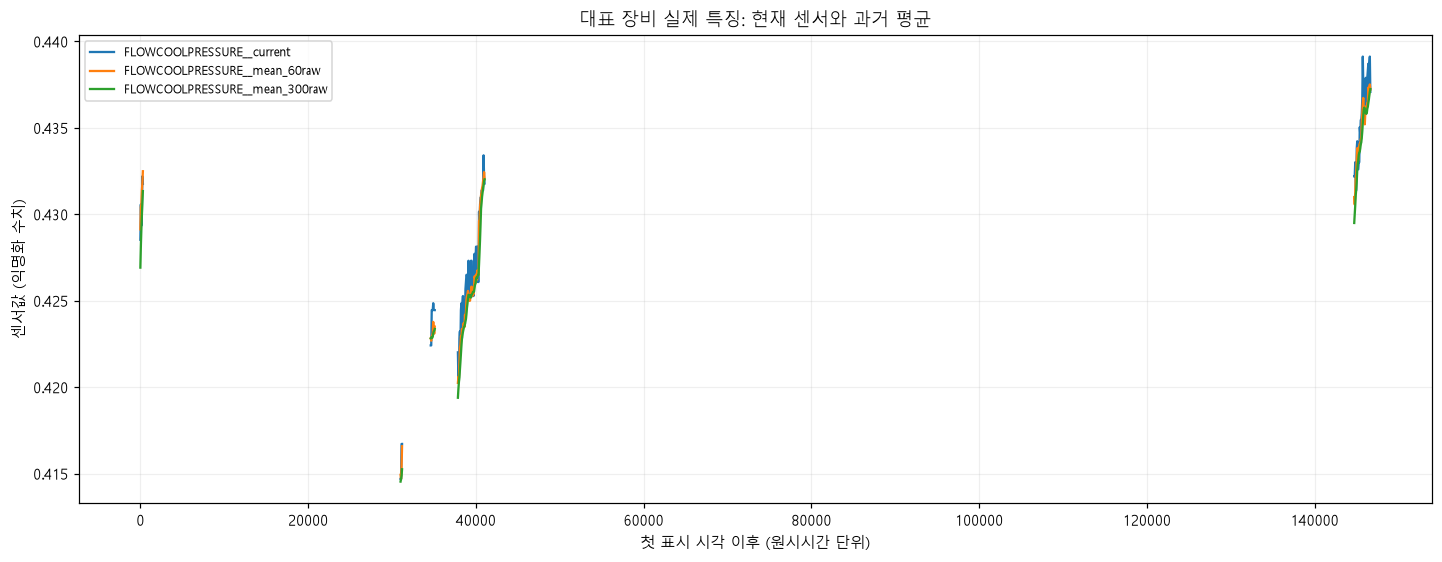

In [3]:
import duckdb
conn=duckdb.connect();conn.execute("SET memory_limit='1GB'")
path=str(DEST/"training/01M01/dataset.parquet")
sample=conn.execute("SELECT time,source_max_time,history_min_time,FLOWCOOLPRESSURE__current,FLOWCOOLPRESSURE__mean_60raw,FLOWCOOLPRESSURE__mean_300raw FROM read_parquet(?) ORDER BY time LIMIT 120",[path]).df()
display(sample.head(8))
fig,ax=plt.subplots(figsize=(13,5),layout="constrained")
for col in ("FLOWCOOLPRESSURE__current","FLOWCOOLPRESSURE__mean_60raw","FLOWCOOLPRESSURE__mean_300raw"):
    y=sample[col].copy();y.loc[sample.time.diff()>72]=np.nan
    ax.plot(sample.time-sample.time.min(),y,label=col)
ax.set(title="대표 장비 실제 특징: 현재 센서와 과거 평균",xlabel="첫 표시 시각 이후 (원시시간 단위)",ylabel="센서값 (익명화 수치)")
ax.legend(fontsize=8);ax.grid(alpha=.2);save_figure(fig,"causal_feature_example")
assert (sample.source_max_time<=sample.time).all()
conn.close()

## 장비 평가와 시간 순서 검증

장비 분할은 번호 접두어 01~06 학습, 07~08 검증, 09~10 평가로 고정했습니다. 같은 접두어의 M01/M02도 같은 쪽에 둡니다. 분할을 고장 분포나 성능에 맞춰 재선정하지 않았습니다.

별도 시간 분할은 각 장비 원시 측정 범위의 60/20/20% 경계입니다. 전체 과거 특징 이력과 최대 1800 원시단위의 미래 타깃 구간이 경계를 넘으면 `purged`로 표시합니다. 같은 이벤트의 양성 anchor와 중첩 이력이 서로 다른 분할에 걸치지 않는지 검증했습니다. 두 분할 방식은 별도 평가 설계이며 섞어서 사용하지 않습니다.

In [4]:
base=ready.query("fault_code=='any' and horizon_raw==1800")
display(base.groupby(["Tool","split_tool","split_time"])[["rows","positive","negative","unknown"]].sum())
for scheme in ("split_tool","split_time"):
    display(Markdown(f"**{scheme}별 클래스 분포 — 통합 타깃**"))
    display(ready.query("fault_code=='any'").groupby([scheme,"horizon_raw"])[["rows","positive","negative","unknown"]].sum())
event_support=pd.DataFrame(summary["observed_positive_events"])
display(event_support.groupby(["scheme","split","fault_code","horizon_raw"]).event_key.nunique().rename("양성 anchor로 관측된 고유 이벤트 수").to_frame())
display(pd.DataFrame(summary["temporal_intervals"]))
display(Markdown("고장 이력의 이벤트 수와 실제 이력·라벨이 갖춰진 양성 anchor의 이벤트 수는 다릅니다. 데이터 공백과 엄격한 충분성 조건으로 누락되는 이벤트를 성능 평가 시 숨기지 않아야 합니다. 검증·평가의 양성/음성 비율은 재표본화하지 않았습니다."))

rows  positive  negative  unknown
Tool  split_tool split_time                                    
01M01 train      evaluation   8929         0         0     8929
                 train       45845        61     18993    26791
                 validation  11647         0         0    11647
01M02 train      evaluation  31994       325         0    31669
                 purged         67         0         7       60
...                            ...       ...       ...      ...
10M01 evaluation evaluation     95        30         0       65
                 train       24683       186      2988    21509
                 validation   6762         0         0     6762
10M02 evaluation train       26432         0         0    26432
                 validation   1517         0         0     1517

[67 rows x 4 columns]

**split_tool별 클래스 분포 — 통합 타깃**

rows  positive  negative  unknown
split_tool horizon_raw                                      
evaluation 300           171733       192     39900   131641
           600           171733       345     30125   141263
           1800          171733       789     19430   151514
train      300          1109917       838    549711   559368
           600          1109917      1541    467421   640955
           1800         1109917      3787    285269   820861
validation 300           185120       200    107131    77789
           600           185120       363     75128   109629
           1800          185120       754     39016   145350

**split_time별 클래스 분포 — 통합 타깃**

rows  positive  negative  unknown
split_time horizon_raw                                     
evaluation 300          213514       261     14137   199116
           600          213514       475      9890   203149
           1800         213514      1171      4074   208269
purged     300             236         0        87      149
           600             236         0        67      169
           1800            236         0        20      216
train      300          957888       731    584132   373025
           600          957888      1332    479035   477521
           1800         957888      3103    291648   663137
validation 300          295132       238     98386   196508
           600          295132       442     83682   211008
           1800         295132      1056     47973   246103

양성 anchor로 관측된 고유 이벤트 수
scheme     split      fault_code horizon_raw                         
split_time evaluation f1         300                               35
                                 600                               35
                                 1800                              35
                      f2         300                               12
                                 600                               12
                                 1800                              12
                      f3         300                                9
                                 600                                9
                                 1800                               9
           train      f1         300                               85
                                 600                               85
                                 1800                              85
                      f2         300                               34
                                 600                               34
                                 1800                              34
                      f3         300                               38
                                 600                               38
                                 1800                              38
           validation f1         300                               36
                                 600                               36
                                 1800                              36
                      f2         300                               13
                                 600                               13
                                 1800                              13
                      f3         300                                7
                                 600                                7
                                 1800                               7
split_tool evaluation f1         300                               30
                                 600                               30
                                 1800                              30
                      f2         300                               11
                                 600                               11
                                 1800                              11
                      f3         300                                4
                                 600                                4
                                 1800                               4
           train      f1         300                              108
                                 600                              108
                                 1800                             108
                      f2         300                               30
                                 600                               30
                                 1800                              30
                      f3         300                               43
                                 600                               43
                                 1800                              43
           validation f1         300                               18
                                 600                               18
                                 1800                              18
                      f2         300                               18
                                 600                               18
                                 1800                              18
                      f3         300                                7
                                 600                                7
                                 1800                               7

,Tool,split_time,history_min,target_max,rows
0,01M02,train,3283862.0,25187402.0,147739
1,03M02,evaluation,35992740.0,43974422.0,9309
2,04M02,validation,27165660.0,34795800.0,47077
3,07M02,evaluation,32993460.0,37150860.0,2953
4,09M02,evaluation,37753740.0,45680040.0,12090
5,02M01,evaluation,26668200.0,29734620.0,6491
6,05M02,train,3324242.0,27175922.0,7918
7,06M01,train,3321122.0,26347442.0,30037
8,01M01,evaluation,35099282.0,42037680.0,8929
9,04M01,train,3292502.0,27465722.0,30388


고장 이력의 이벤트 수와 실제 이력·라벨이 갖춰진 양성 anchor의 이벤트 수는 다릅니다. 데이터 공백과 엄격한 충분성 조건으로 누락되는 이벤트를 성능 평가 시 숨기지 않아야 합니다. 검증·평가의 양성/음성 비율은 재표본화하지 않았습니다.

## 전체 상태 모델과 가동 구간 모델의 학습 가능 크기

`training/`에는 특징이 준비되고 12개 타깃 중 하나 이상 알려진 행만 있습니다. 각 모델은 해당 **target IS NOT NULL**을 추가 필터링해야 합니다. 전체 상태 모델은 모든 Stage, 가동 모델은 **Stage>0**으로 같은 분할을 필터링합니다. 학습 불균형 처리는 아직 하지 않았으며 검증·평가는 동일 주기의 실제 분포를 유지합니다.

positive  negative  unknown  타깃별 학습 가능 수
fault_code horizon_raw                                          
any        300              1230    696742   768798       697972
           600              2249    572674   891847       574923
           1800             5330    343715  1117725       349045
f1         300               707   1282292   183771      1282999
           600              1264   1035137   430369      1036401
           1800             2994    612296   851480       615290
f2         300               277   1072238   394255      1072515
           600               530    849881   616359       850411
           1800             1283    498396   967091       499679
f3         300               256    982948   483566       983204
           600               487    824811   641472       825298
           1800             1245    494353   971172       495598

positive  negative  unknown  가동 타깃별 학습 가능 수
fault_code horizon_raw                                             
any        300              1171    660704   682828          661875
           600              2145    539842   802716          541987
           1800             5097    323305  1016301          328402
f1         300               653   1181472   162578         1182125
           600              1170    942775   400758          943945
           1800             2791    553134   788778          555925
f2         300               272    978484   365947          978756
           600               520    763880   580303          764400
           1800             1253    442720   900730          443973
f3         300               256    940227   404220          940483
           600               487    785866   558350          786353
           1800             1245    470140   873318          471385

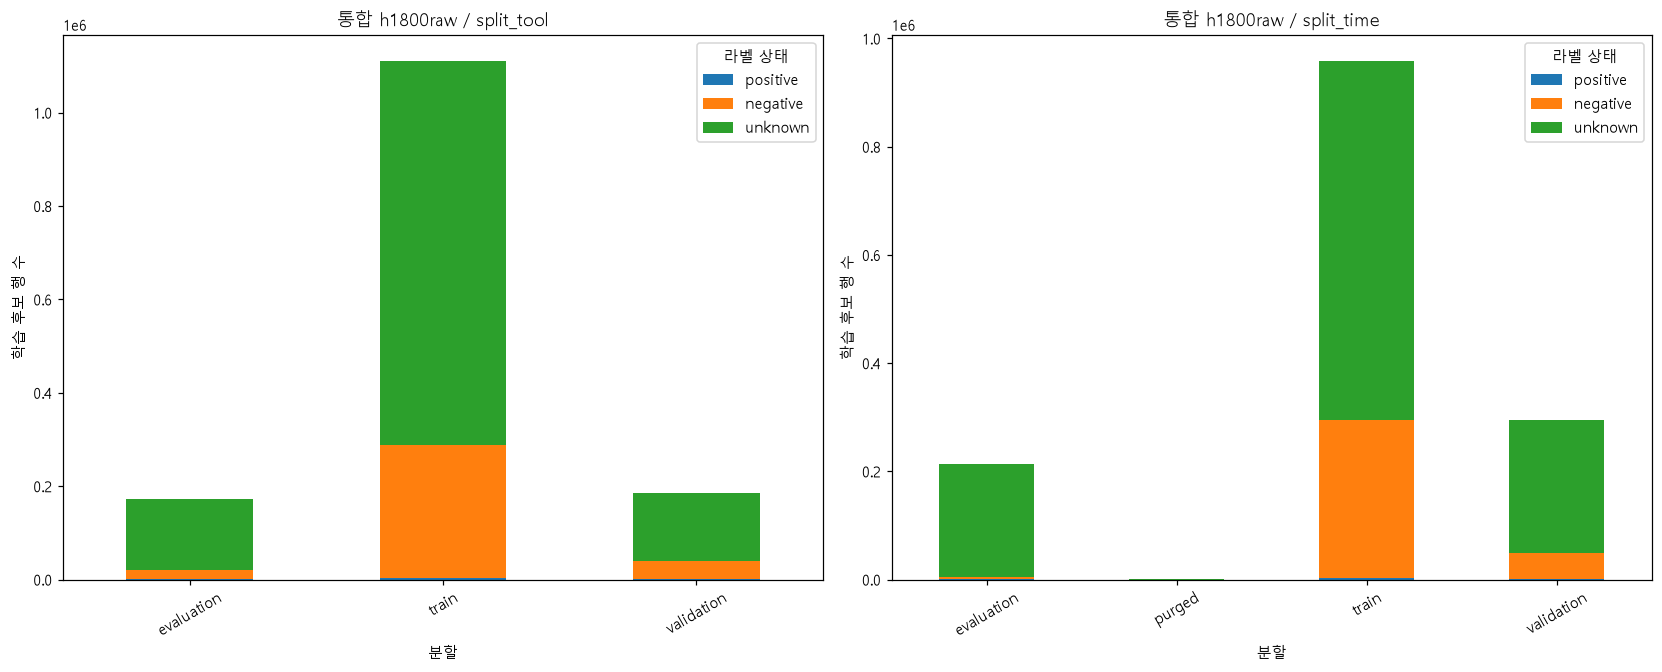

,Parquet bytes
observations,1557496108
segments,4127486
labels,509209702
features,2453976054
training,419098031


적어도 하나의 타깃이 알려진 물리 학습 파일은 **1,466,770행**, **0.390 GiB**입니다. 각 타깃과 분할에 사용 가능한 실제 수는 위 표를 기준으로 합니다. 물리 분 단위가 미확정이므로 현재 사용 가능한 것은 원시시간 구간 예측 데이터셋입니다.

In [5]:
sizes=ready.groupby(["fault_code","horizon_raw"])[["positive","negative","unknown"]].sum()
sizes["타깃별 학습 가능 수"]=sizes.positive+sizes.negative
display(sizes)
active=ready[ready.state_group=="stage_positive"].groupby(["fault_code","horizon_raw"])[["positive","negative","unknown"]].sum()
active["가동 타깃별 학습 가능 수"]=active.positive+active.negative
display(active)
fig,axes=plt.subplots(1,2,figsize=(15,6),layout="constrained")
for ax,scheme in zip(axes,("split_tool","split_time")):
    x=ready.query("fault_code=='any' and horizon_raw==1800").groupby(scheme)[["positive","negative","unknown"]].sum()
    x.plot.bar(stacked=True,ax=ax)
    ax.set(title=f"통합 h1800raw / {scheme}",xlabel="분할",ylabel="학습 후보 행 수");ax.legend(title="라벨 상태");ax.tick_params(axis="x",rotation=30)
save_figure(fig,"training_split_distribution")
display(pd.Series(summary["sizes_bytes"],name="Parquet bytes").to_frame())
display(Markdown(f"적어도 하나의 타깃이 알려진 물리 학습 파일은 **{summary['training_rows']:,}행**, **{summary['sizes_bytes']['training']/1024**3:.3f} GiB**입니다. 각 타깃과 분할에 사용 가능한 실제 수는 위 표를 기준으로 합니다. 물리 분 단위가 미확정이므로 현재 사용 가능한 것은 원시시간 구간 예측 데이터셋입니다."))

## 누수 검증과 남은 제한

라벨 근거, 시각 키, 키 유일성, 유한 특징, 통합 라벨의 3값 논리, 원본 메타데이터, 이벤트 공유, 시간 범위 중첩 검사를 통과해야 결과 파일을 사용합니다. 아래 단위 테스트는 실제 첫 연속 관측 일부에서 미래 값 변경과 청크 크기 변경을 적용한 검증이며 실험 성능 수치가 아닙니다.

In [6]:
import unittest
suite=unittest.TestLoader().discover(str(ROOT/"tests"),pattern="test_dataset_pipeline.py")
test_result=unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()
display(pd.Series({"전체 검사 통과":summary["all_checks_passed"],"미래 관측 입력":False,
                   "공유 양성 이벤트":len(summary["shared_positive_events"]),"시간 분할 중첩":len(summary["overlapping_time_splits"]),
                   "원본 메타데이터 유지":summary["source_metadata_unchanged"],"공식 test 정답 사용":False}).to_frame("검증 결과"))
display(Markdown("물리 시간 단위, 고장 이력의 절대적 완전성, Stage>0의 실제 가동/정상 의미, 동시각 배치의 현장 도착 순서는 미확정입니다. 긴 공백·TTF 결측·부족한 이력 때문에 사용 가능한 이벤트가 감소합니다. 공식 test는 로컬 정답이 없으므로 현재 모델 평가 계획은 내부 장비/시간 분할입니다. 모델 학습·스케일링·대치·클래스 재표본화는 수행하지 않았습니다."))

test_feature_input_rejects_target (test_dataset_pipeline.PipelineTests.test_feature_input_rejects_target) ... 

ok


test_future_perturbation_and_chunk_equivalence (test_dataset_pipeline.PipelineTests.test_future_perturbation_and_chunk_equivalence) ... 

ok


test_label_evidence_gap_and_fault_boundary (test_dataset_pipeline.PipelineTests.test_label_evidence_gap_and_fault_boundary) ... 

ok


... (3 outputs left out)

ok


----------------------------------------------------------------------
Ran 5 tests in 0.976s

OK


,검증 결과
전체 검사 통과,True
미래 관측 입력,False
공유 양성 이벤트,0
시간 분할 중첩,0
원본 메타데이터 유지,True
공식 test 정답 사용,False


물리 시간 단위, 고장 이력의 절대적 완전성, Stage>0의 실제 가동/정상 의미, 동시각 배치의 현장 도착 순서는 미확정입니다. 긴 공백·TTF 결측·부족한 이력 때문에 사용 가능한 이벤트가 감소합니다. 공식 test는 로컬 정답이 없으므로 현재 모델 평가 계획은 내부 장비/시간 분할입니다. 모델 학습·스케일링·대치·클래스 재표본화는 수행하지 않았습니다.